**Setup.** Run this cell first: it locates the data files this notebook reads. On Google
Colab it downloads them (the `Data/` and `Support/` folders) from the book's GitHub
repository; on your computer, run the notebook from the `notebooks/` folder.

In [1]:
import os
import sys
path = ''
if 'google.colab' in sys.modules and not os.path.isdir('Data'):
    if not os.path.isdir('statsbook'):
        os.system('git clone -q --depth 1 --filter=blob:none --sparse '
                  'https://github.com/vzavala/StatsBook-GitBook.git statsbook')
        os.system('git -C statsbook sparse-checkout set notebooks/Data notebooks/Support')
    path = 'statsbook/notebooks/'

CNN classification of flow-cytometry scatter fields: is endotoxin present? (Python version of
`ch6_cnn_endotoxins_caseI.m`, Victor Z, UW-Madison, 2020; uses PyTorch.)

| Slides | Python | Meaning |
|---|---|---|
| $\mathbf{X}_\omega$ | `X[w, 0]` | $50\times 50$ grayscale scatter field |
| $y_\omega$ | `y` | class: `bipolar` (no endotoxin) or `radial` (endotoxin) |
| $\Theta^I$, $\theta^I$ | `cnn[0].weight`, `cnn[0].bias` | $3\times 3$ filter and bias of the convolutional layer |
| $\mathbf{A}=\mathbf{X}*\Theta^I+\theta^I$, $\mathbf{Z}=h(\mathbf{A})$ | `cnn[0]`, `cnn[1]` | evidence and ReLU activation |
| $NN(\mathbf{w},\gamma)$ | `cnn[3]` | fully connected layer (2 classes, softmax) |
| $L(\beta)$ | `loss_fn` | cross-entropy (log) loss |

As in the Matlab script: one $3\times 3$ filter with "same" padding, ReLU, a fully connected
layer, 15 training images per class, the rest for validation, 40 epochs of SGD with momentum.

In [2]:
import glob
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from skimage import io
from sklearn.metrics import confusion_matrix

folder = path + 'Data/Endotoxins_CaseI/Gray'
classes = sorted(os.listdir(folder))
X, y = [], []
for c, name in enumerate(classes):
    for f in sorted(glob.glob(f'{folder}/{name}/*.png')):
        X.append(io.imread(f).astype(np.float32) / 255)
        y.append(c)
X, y = np.array(X)[:, None], np.array(y)
print("classes:", classes, " images per class:", np.bincount(y), " image size:", X.shape[2:])

rng = np.random.default_rng(0)
train = np.concatenate([rng.choice(np.where(y == c)[0], 15, replace=False) for c in range(len(classes))])
valid = np.setdiff1d(np.arange(len(y)), train)
X_t = torch.tensor(X - X[train].mean(axis=0, keepdims=True))      # zero-center (as Matlab's input layer)
y_t = torch.tensor(y)

classes: ['bipolar', 'radial']  images per class: [49 49]  image size: (50, 50)


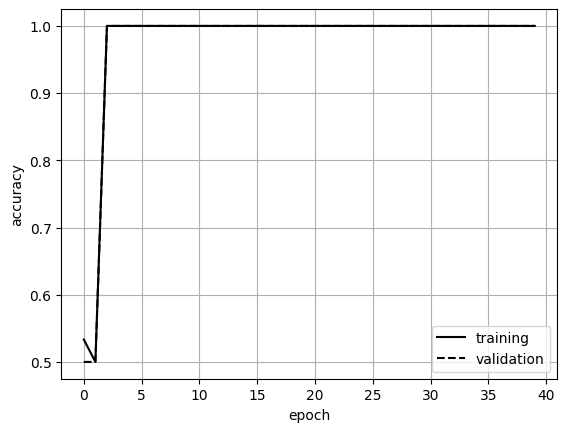

training accuracy = 100%,  validation accuracy = 100%


In [3]:
torch.manual_seed(0)
cnn = nn.Sequential(nn.Conv2d(1, 1, kernel_size=3, padding=1),   # A = X * Theta + theta
                    nn.ReLU(),                                     # Z = h(A)
                    nn.Flatten(),                                  # feature vector w
                    nn.Linear(50 * 50, len(classes)))              # fully connected layer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(cnn.parameters(), lr=0.01, momentum=0.9)

history = []
for epoch in range(40):
    perm = torch.tensor(train)[torch.randperm(len(train))]
    for b in range(0, len(perm), 10):
        idx = perm[b:b + 10]
        optimizer.zero_grad()
        loss = loss_fn(cnn(X_t[idx]), y_t[idx])
        loss.backward()
        optimizer.step()
    with torch.no_grad():
        acc = [(cnn(X_t[ids]).argmax(1) == y_t[ids]).float().mean().item() for ids in (train, valid)]
    history.append(acc)

history = np.array(history)
plt.plot(history[:, 0], 'k-', label='training'); plt.plot(history[:, 1], 'k--', label='validation')
plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.legend(); plt.grid(True)
plt.show()
print(f"training accuracy = {history[-1, 0]:.0%},  validation accuracy = {history[-1, 1]:.0%}")

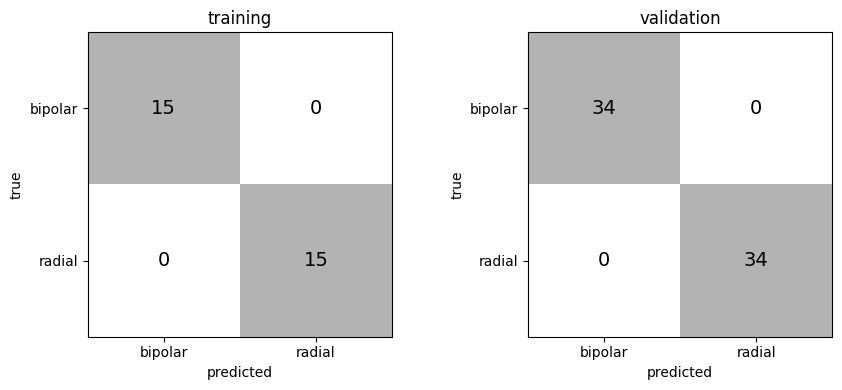

In [4]:
with torch.no_grad():
    y_hat = cnn(X_t).argmax(1).numpy()
fig, axs = plt.subplots(1, 2, figsize=(9, 4))
for ax, ids, title in ((axs[0], train, 'training'), (axs[1], valid, 'validation')):
    cm = confusion_matrix(y[ids], y_hat[ids], labels=range(len(classes)))
    ax.imshow(cm, cmap='Greys', alpha=0.3)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha='center', va='center', fontsize=14)
    ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes)
    ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(title)
plt.tight_layout()
plt.show()

The learned filter $\Theta$ and the activated images $\mathbf{Z}=h(\mathbf{X}*\Theta+\theta)$ for nine
validation images.

Theta =
 [[-0.349 -0.307 -0.742]
 [-0.711 -0.499 -0.039]
 [-0.235  0.313  0.159]]


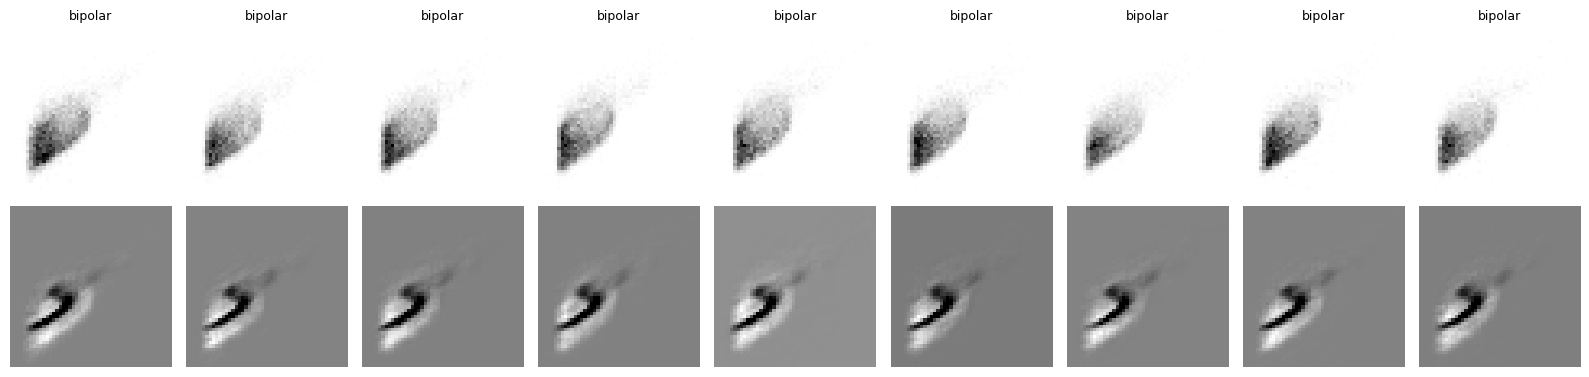

In [5]:
print("Theta =\n", np.round(cnn[0].weight.detach().numpy()[0, 0], 3))
with torch.no_grad():
    Z = cnn[1](cnn[0](X_t[valid[:9]])).numpy()
fig, axs = plt.subplots(2, 9, figsize=(16, 4))
for k in range(9):
    axs[0, k].imshow(X[valid[k], 0], cmap='gray'); axs[0, k].set_title(classes[y[valid[k]]], fontsize=9)
    axs[1, k].imshow(Z[k, 0], cmap='gray')
for ax in axs.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()